In [6]:
import pandas as pd

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df = df.dropna(subset=["TotalCharges"]).copy()

df = df.drop(columns=["customerID"])

In [8]:
df.shape

(7032, 20)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 
 17  

In [10]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

In [11]:
X.shape

(7032, 19)

In [12]:
y.head()

0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: object

In [13]:
y = y.map({
    "No": 0,
    "Yes": 1
})

In [14]:
y.value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

In [15]:
categorical_cols = X.select_dtypes(
    include="object"
).columns.tolist()

categorical_cols

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [16]:
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

numerical_cols

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

In [17]:
X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)
X_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [18]:
X_encoded.shape

(7032, 30)

In [19]:
X_encoded.columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')

In [20]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

y = y.map({
    "No": 0,
    "Yes": 1
})

categorical_cols = X.select_dtypes(
    include="object"
).columns.tolist()

X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)

In [21]:
X_encoded.shape

(7032, 30)

In [22]:
X_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [25]:
X_train.shape

(5625, 30)

In [26]:
X_test.shape

(1407, 30)

In [27]:
y_train.value_counts(normalize=True)

Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64

In [28]:
y_test.value_counts(normalize=True)

Churn
0    0.734186
1    0.265814
Name: proportion, dtype: float64

Import Model

In [29]:
from sklearn.linear_model import LogisticRegression

Build Model

In [30]:
model = LogisticRegression(max_iter=1000)

Training Model

In [31]:
model.fit(X_train, y_train)

/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_point

LogisticRegression(max_iter=1000)

In [32]:
y_pred = model.predict(X_test)

/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [33]:
from sklearn.metrics import accuracy_score

In [34]:
accuracy = accuracy_score(y_test, y_pred)
accuracy

0.8017057569296375

In [35]:
from sklearn.metrics import classification_report

In [36]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.88      0.87      1033
           1       0.64      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [37]:
from sklearn.metrics import confusion_matrix

In [38]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[914, 119],
       [160, 214]])

Logistic Regression Baseline:

The model achieved an accuracy of approximately 80.2%. For churned customers, precision was 0.64, recall was 0.57, and the F1-score was 0.61. While the model performs well at identifying non-churn customers, it misses a substantial proportion of actual churn cases, indicating room for improvement in churn detection.

In [39]:
from sklearn.ensemble import RandomForestClassifier

In [40]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

In [41]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [42]:
rf_pred = rf_model.predict(X_test)

In [43]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, rf_pred)

0.7874911158493249

In [44]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [45]:
confusion_matrix(y_test, rf_pred)

array([[918, 115],
       [184, 190]])

Random Forest Model：

The Random Forest achieved an accuracy of approximately 78.7%. For churned customers, precision was 0.62, recall was 0.51, and the F1-score was 0.56. Compared with Logistic Regression, the Random Forest showed lower overall accuracy and weaker churn detection performance, particularly in recall.

In [46]:
from sklearn.ensemble import GradientBoostingClassifier

In [47]:
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

In [48]:
gb_model.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=0.05, n_estimators=200,
                           random_state=42)

In [49]:
gb_pred = gb_model.predict(X_test)

In [50]:
accuracy_score(y_test, gb_pred)

0.7960199004975125

In [51]:
print(classification_report(y_test, gb_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



In [52]:
confusion_matrix(y_test, gb_pred)

array([[922, 111],
       [176, 198]])

In [53]:
from sklearn.metrics import roc_auc_score

In [54]:
lr_prob = model.predict_proba(X_test)[:, 1]

lr_auc = roc_auc_score(y_test, lr_prob)

lr_auc

/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


np.float64(0.8364053092855552)

In [55]:
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, rf_prob)

rf_auc

np.float64(0.8183733583198307)

In [56]:
gb_prob = gb_model.predict_proba(X_test)[:, 1]

gb_auc = roc_auc_score(y_test, gb_prob)

gb_auc

np.float64(0.8406010736601249)

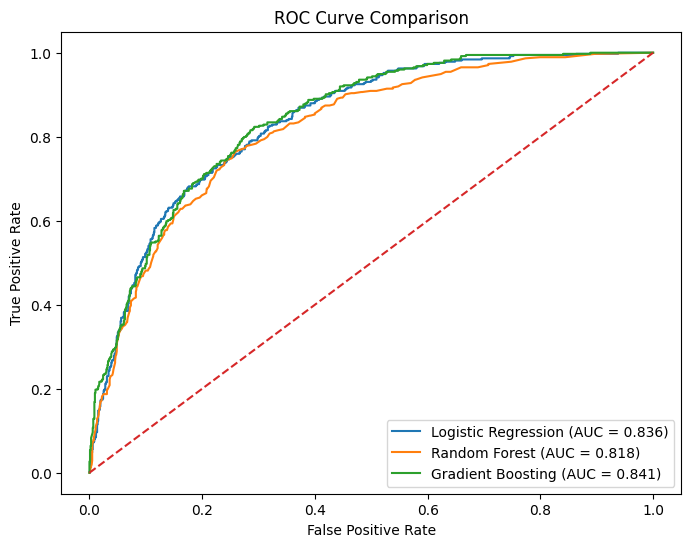

In [57]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
gb_fpr, gb_tpr, _ = roc_curve(y_test, gb_prob)

plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {lr_auc:.3f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
plt.plot(gb_fpr, gb_tpr, label=f"Gradient Boosting (AUC = {gb_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()

plt.show()

ROC-AUC Comparison

Gradient Boosting achieved the highest ROC-AUC of 0.841, slightly outperforming Logistic Regression (0.836) and Random Forest (0.818). All three models performed substantially better than random classification.

In [58]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, gb_pred)
    ],
    "ROC_AUC": [
        lr_auc,
        rf_auc,
        gb_auc
    ]
})

comparison

,Model,Accuracy,ROC_AUC
0,Logistic Regression,0.801706,0.836405
1,Random Forest,0.787491,0.818373
2,Gradient Boosting,0.796020,0.840601


In [59]:
from sklearn.metrics import precision_score, recall_score, f1_score

comparison["Precision_Churn"] = [
    precision_score(y_test, y_pred),
    precision_score(y_test, rf_pred),
    precision_score(y_test, gb_pred)
]

comparison["Recall_Churn"] = [
    recall_score(y_test, y_pred),
    recall_score(y_test, rf_pred),
    recall_score(y_test, gb_pred)
]

comparison["F1_Churn"] = [
    f1_score(y_test, y_pred),
    f1_score(y_test, rf_pred),
    f1_score(y_test, gb_pred)
]

comparison.round(3)

,Model,Accuracy,ROC_AUC,Precision_Churn,Recall_Churn,F1_Churn
0,Logistic Regression,0.802,0.836,0.643,0.572,0.605
1,Random Forest,0.787,0.818,0.623,0.508,0.560
2,Gradient Boosting,0.796,0.841,0.641,0.529,0.580


In [60]:
threshold = 0.45

lr_pred_045 = (lr_prob >= threshold).astype(int)

In [61]:
print(classification_report(y_test, lr_pred_045))

              precision    recall  f1-score   support

           0       0.87      0.85      0.86      1033
           1       0.61      0.63      0.62       374

    accuracy                           0.79      1407
   macro avg       0.74      0.74      0.74      1407
weighted avg       0.80      0.79      0.80      1407



In [62]:
confusion_matrix(y_test, lr_pred_045)

array([[880, 153],
       [137, 237]])

In [63]:
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for t in thresholds:
    pred = (lr_prob >= t).astype(int)

    results.append({
        "Threshold": t,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred)
    })

threshold_results = pd.DataFrame(results)

threshold_results.round(3)

,Threshold,Precision,Recall,F1,Accuracy
0,0.30,0.514,0.759,0.613,0.745
1,0.35,0.544,0.722,0.621,0.765
2,0.40,0.577,0.682,0.625,0.783
3,0.45,0.608,0.634,0.620,0.794
4,0.50,0.643,0.572,0.605,0.802
5,0.55,0.673,0.489,0.567,0.801
6,0.60,0.686,0.385,0.493,0.790


Threshold Tuning

Reducing the classification threshold from 0.50 to 0.40 increased churn recall from 0.572 to 0.682 and improved the churn F1-score from 0.605 to 0.625. Although precision and overall accuracy decreased slightly, a threshold of 0.40 provides a better balance for identifying customers at risk of churn.

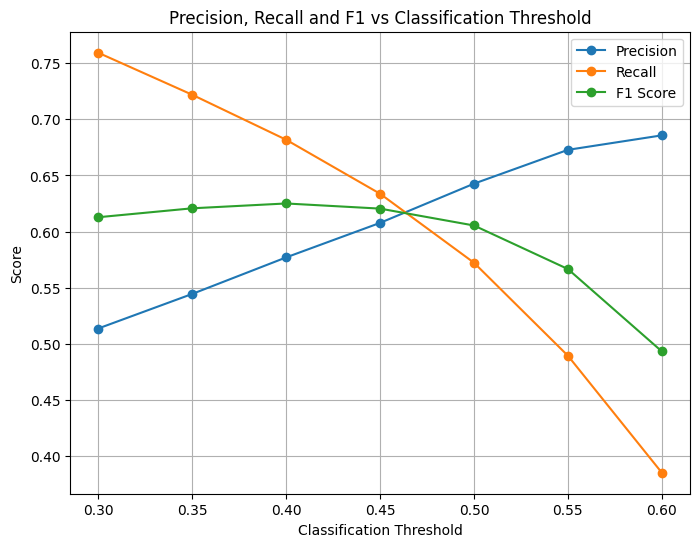

In [64]:
plt.figure(figsize=(8, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Classification Threshold")
plt.legend()
plt.grid(True)

plt.show()

Threshold Selection

As the classification threshold increases, precision improves while recall decreases. The F1-score reaches its highest value at a threshold of 0.40, indicating the best balance between precision and recall for churn detection in this model.